# Test of part A

In [16]:
%load_ext autoreload
%autoreload 2

import numpy as np
import time
from PIL import Image
import matplotlib.pyplot as plt

from filters import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Masks from the instructions (given).

In [17]:
identity_5 = np.zeros((5, 5)); identity_5[2, 2] = 1
mean_5 = np.ones((5, 5))                     # it normalizes itself (/25) in prepare_mask
gaussian_5 = np.array([[1, 4, 6, 4, 1],
                       [4, 16, 24, 16, 4],
                       [6, 24, 36, 24, 6],
                       [4, 16, 24, 16, 4],
                       [1, 4, 6, 4, 1]])     # it normalizes itself (/256)
laplacian = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
sobel_h = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])

Test identities.

In [18]:
rng = np.random.default_rng(0)
img_random = rng.integers(0, 256, (40, 50, 3), dtype=np.uint8)

out = filter_sequential(img_random, identity_5)
print("Identity: output == input ->", np.array_equal(out, img_random))
print("Same shape ->", out.shape == img_random.shape, out.shape)

Identity: output == input -> True
Same shape -> True (40, 50, 3)


test constant img 128 + mean 5×5

In [19]:
img_128 = np.full((20, 20, 3), 128, dtype=np.uint8)
out = filter_sequential(img_128, mean_5)

print("Everything 128 ->", np.all(out == 128))
print("Corners:", out[0, 0], out[0, -1], out[-1, 0], out[-1, -1])

# If the padding were wrong (zero padding), the corners would be below 128.

Everything 128 -> True
Corners: [128 128 128] [128 128 128] [128 128 128] [128 128 128]


test img 250 + sharpen

In [20]:
img_250 = np.full((20, 20, 3), 250, dtype=np.uint8)
out = filter_sequential(img_250, sharpen)

print("Min:", out.min(), "| Max:", out.max())
print("No dark pixels ->", out.min() >= 250)

Min: 250 | Max: 250
No dark pixels -> True


corner pixel demonstration.

In [21]:
g = np.arange(1, 26, dtype=np.uint8).reshape(5, 5)
print("Original Image 5x5:\n", g)

padded = pad_replicate(to_3d(g), 2, 2)[:, :, 0]
print("\nWith padding (mask 5x5, a=b=2):\n", padded)

print("\nTimes that the top-left corner I(0,0)=1 appears in the window of (0,0):",
      np.sum(padded[0:5, 0:5] == 1))

Original Image 5x5:
 [[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]]

With padding (mask 5x5, a=b=2):
 [[ 1  1  1  2  3  4  5  5  5]
 [ 1  1  1  2  3  4  5  5  5]
 [ 1  1  1  2  3  4  5  5  5]
 [ 6  6  6  7  8  9 10 10 10]
 [11 11 11 12 13 14 15 15 15]
 [16 16 16 17 18 19 20 20 20]
 [21 21 21 22 23 24 25 25 25]
 [21 21 21 22 23 24 25 25 25]
 [21 21 21 22 23 24 25 25 25]]

Times that the top-left corner I(0,0)=1 appears in the window of (0,0): 9


saturation test by hand 

In [22]:
# Ejemplo del enunciado: centro 200, 4 vecinos a 100 -> 5*200 - 4*100 = 600 -> 255
small = np.full((3, 3), 100, dtype=np.uint8)
small[1, 1] = 200
out = filter_sequential(small, sharpen)
print("Central Pixel:", out[1, 1], "(expected 255)")

Central Pixel: 255 (expected 255)


mask validation

In [23]:
for bad in [np.ones((2, 3)), np.ones((7, 7)), np.ones(3), np.ones((4, 4))]:
    try:
        validate_mask(bad)
        print("ERROR: got accepted", bad.shape)
    except ValueError as e:
        print("rejected correctly:", e)

validate_mask(np.ones((1, 1))); validate_mask(np.ones((3, 5)))
print("1x1 y 3x5 accepted")

rejected correctly: The mask has 2 rows: it must be an odd number (1, 3 or 5).
rejected correctly: The mask has 7 rows: the maximum is 5.
rejected correctly: The mask must be 2D and has 1 dimensions.
rejected correctly: The mask has 4 rows: it must be an odd number (1, 3 or 5).
1x1 y 3x5 accepted


correlation vs convolution with Sobel

In [24]:
out_corr = filter_sequential(img_random, sobel_h, is_conv=0, norm=1)
out_conv = filter_sequential(img_random, sobel_h, is_conv=1, norm=1)
print("Equals?", np.array_equal(out_corr, out_conv))   # False: Sobel not symmetric

out_corr = filter_sequential(img_random, gaussian_5, is_conv=0)
out_conv = filter_sequential(img_random, gaussian_5, is_conv=1)
print("Gaussian equals?", np.array_equal(out_corr, out_conv))   # True:  symmetric mask

Equals? False
Gaussian equals? True


real img

Size: (59, 54, 3)


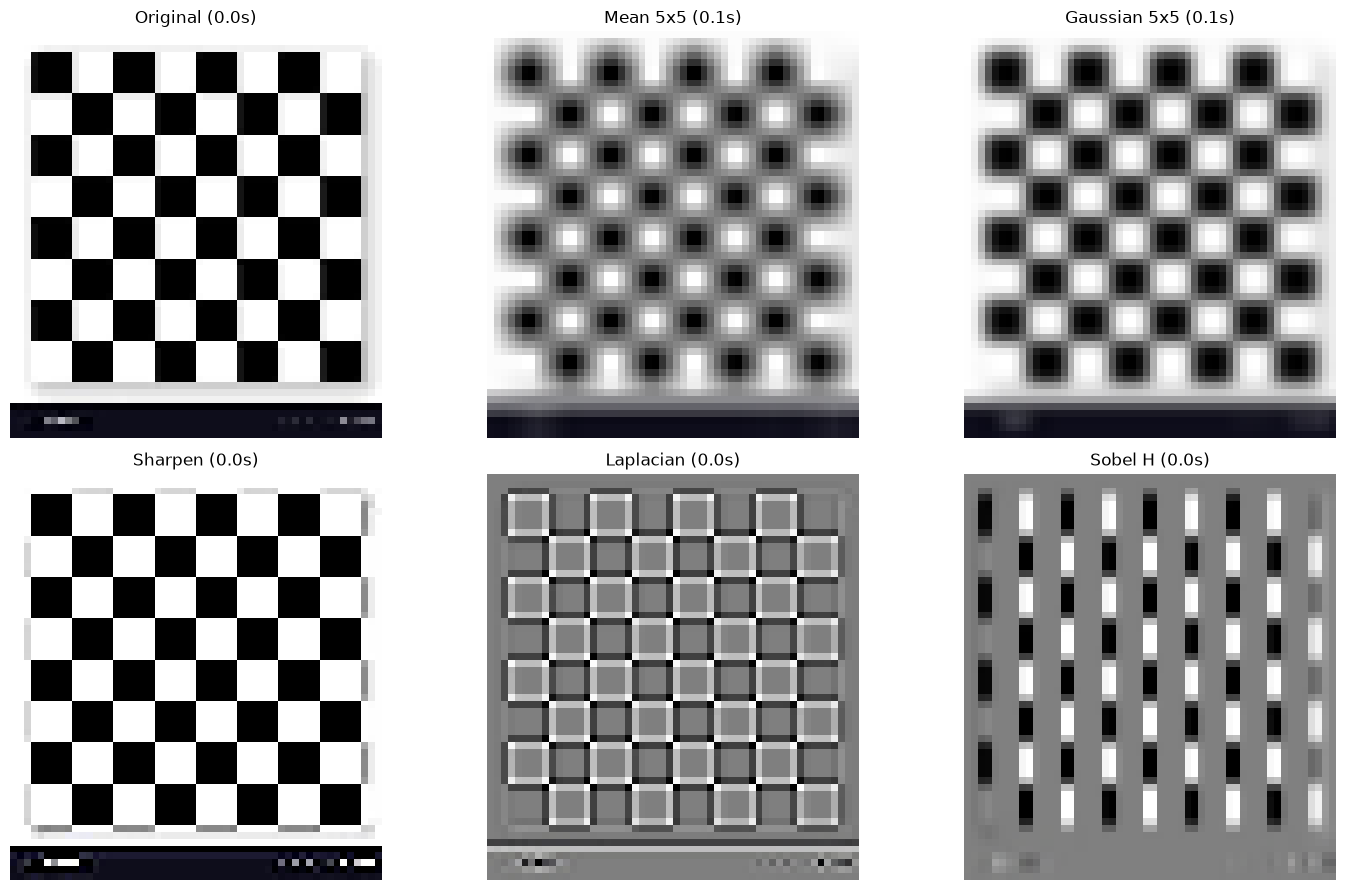

In [25]:
real = np.array(Image.open("images/chess.jpg").convert("RGB"))
real = real[::4, ::4]          # reduces 4 times each side --- quitar para la versión final
print("Size:", real.shape)

masks = [("Original", None), ("Mean 5x5", mean_5), ("Gaussian 5x5", gaussian_5),
         ("Sharpen", sharpen), ("Laplacian", laplacian), ("Sobel H", sobel_h)]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, m) in zip(axes.flat, masks):
    t = time.time()
    if m is None:
        res = real
    else:
        norm = 1 if np.isclose(m.sum(), 0) else 0   # suman 0 -> rescaling
        res = filter_sequential(real, m, is_conv=0, norm=norm)
    ax.imshow(res); ax.set_title(f"{name} ({time.time() - t:.1f}s)"); ax.axis("off")
plt.tight_layout(); plt.show()

Gaussian → Laplacian

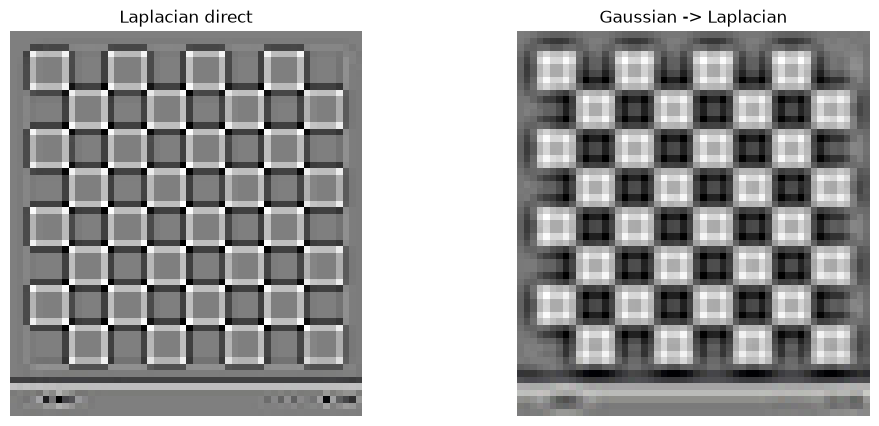

In [26]:
direct = filter_sequential(real, laplacian, norm=1)
smoothed = filter_sequential(real, gaussian_5)
cascade = filter_sequential(smoothed, laplacian, norm=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(direct); axes[0].set_title("Laplacian direct")
axes[1].imshow(cascade); axes[1].set_title("Gaussian -> Laplacian")
for ax in axes: ax.axis("off")
plt.show()

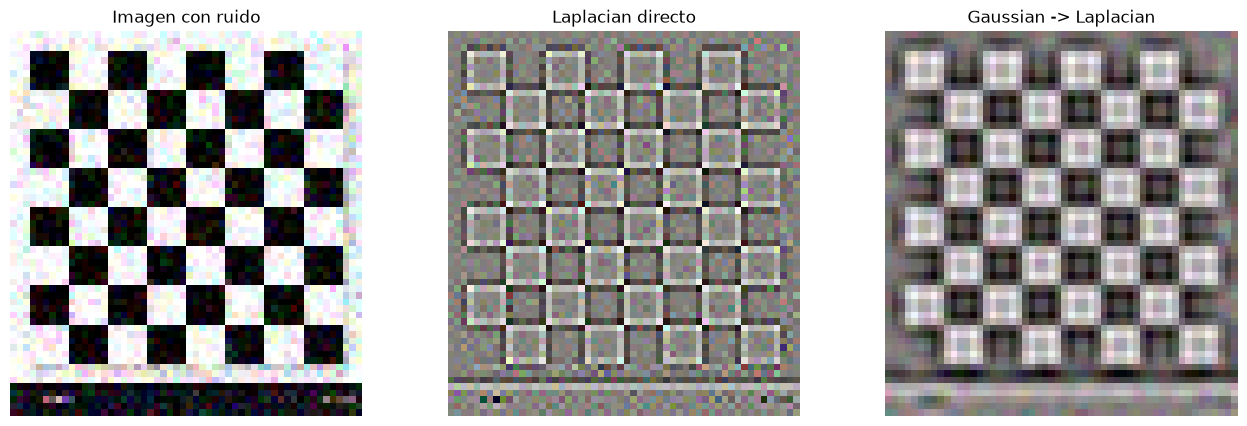

In [27]:
rng = np.random.default_rng(0)
noise = rng.normal(0, 25, real.shape)                       # ruido gaussiano, desviación 25
noisy = np.clip(real.astype(np.float64) + noise, 0, 255).astype(np.uint8)

direct = filter_sequential(noisy, laplacian, norm=1)
cascade = filter_sequential(filter_sequential(noisy, gaussian_5), laplacian, norm=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(noisy); axes[0].set_title("Imagen con ruido")
axes[1].imshow(direct); axes[1].set_title("Laplacian directo")
axes[2].imshow(cascade); axes[2].set_title("Gaussian -> Laplacian")
for ax in axes: ax.axis("off")
plt.show()

hemos comprobado que el Gaussian antes del Laplacian reduce el ruido cuando la imagen tiene ruido, y que en una imagen limpia el coste es que los bordes salen más anchos y menos precisos. Es el compromiso típico de suavizar antes de detectar bordes.